In [24]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [25]:
import matplotlib.pyplot as plt

# Data Reading and Exploration

In [26]:
df=pd.read_csv("Student_Performance.csv")
df

,student_id,age,gender,school_type,parent_education,study_hours,attendance_percentage,internet_access,travel_time,extra_activities,study_method,math_score,science_score,english_score,overall_score,final_grade
0,1,14,male,public,post graduate,3.1,84.3,yes,<15 min,yes,notes,42.7,55.4,57.0,53.1,e
1,2,18,female,public,graduate,3.7,87.8,yes,>60 min,no,textbook,57.6,68.8,64.8,61.3,d
2,3,17,female,private,post graduate,7.9,65.5,no,<15 min,no,notes,84.8,95.0,79.2,89.6,b
3,4,16,other,public,high school,1.1,58.1,no,15-30 min,no,notes,44.4,27.5,54.7,41.6,e
4,5,16,female,public,high school,1.3,61.0,yes,30-60 min,yes,group study,8.9,32.7,30.0,25.4,f
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24995,12047,17,female,public,phd,1.8,55.2,yes,15-30 min,no,mixed,55.8,48.5,46.7,46.1,e
24996,1102,16,female,private,diploma,2.7,97.1,yes,<15 min,no,coaching,64.8,48.2,52.3,56.5,d
24997,4422,19,other,private,post graduate,1.0,63.0,yes,<15 min,no,group study,50.5,20.3,36.1,36.7,f
24998,7858,14,male,private,diploma,1.0,69.4,yes,15-30 min,yes,group study,13.0,34.2,7.3,34.1,f


In [27]:
df.head()

,student_id,age,gender,school_type,parent_education,study_hours,attendance_percentage,internet_access,travel_time,extra_activities,study_method,math_score,science_score,english_score,overall_score,final_grade
0,1,14,male,public,post graduate,3.1,84.3,yes,<15 min,yes,notes,42.7,55.4,57.0,53.1,e
1,2,18,female,public,graduate,3.7,87.8,yes,>60 min,no,textbook,57.6,68.8,64.8,61.3,d
2,3,17,female,private,post graduate,7.9,65.5,no,<15 min,no,notes,84.8,95.0,79.2,89.6,b
3,4,16,other,public,high school,1.1,58.1,no,15-30 min,no,notes,44.4,27.5,54.7,41.6,e
4,5,16,female,public,high school,1.3,61.0,yes,30-60 min,yes,group study,8.9,32.7,30.0,25.4,f


In [28]:
df.tail()

,student_id,age,gender,school_type,parent_education,study_hours,attendance_percentage,internet_access,travel_time,extra_activities,study_method,math_score,science_score,english_score,overall_score,final_grade
24995,12047,17,female,public,phd,1.8,55.2,yes,15-30 min,no,mixed,55.8,48.5,46.7,46.1,e
24996,1102,16,female,private,diploma,2.7,97.1,yes,<15 min,no,coaching,64.8,48.2,52.3,56.5,d
24997,4422,19,other,private,post graduate,1.0,63.0,yes,<15 min,no,group study,50.5,20.3,36.1,36.7,f
24998,7858,14,male,private,diploma,1.0,69.4,yes,15-30 min,yes,group study,13.0,34.2,7.3,34.1,f
24999,11621,18,other,public,no formal,0.7,60.3,yes,30-60 min,no,mixed,36.5,45.1,16.5,31.4,f


In [29]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   student_id             25000 non-null  int64  
 1   age                    25000 non-null  int64  
 2   gender                 25000 non-null  str    
 3   school_type            25000 non-null  str    
 4   parent_education       25000 non-null  str    
 5   study_hours            25000 non-null  float64
 6   attendance_percentage  25000 non-null  float64
 7   internet_access        25000 non-null  str    
 8   travel_time            25000 non-null  str    
 9   extra_activities       25000 non-null  str    
 10  study_method           25000 non-null  str    
 11  math_score             25000 non-null  float64
 12  science_score          25000 non-null  float64
 13  english_score          25000 non-null  float64
 14  overall_score          25000 non-null  float64
 15  final_grade  

In [30]:
df.columns

Index(['student_id', 'age', 'gender', 'school_type', 'parent_education',
       'study_hours', 'attendance_percentage', 'internet_access',
       'travel_time', 'extra_activities', 'study_method', 'math_score',
       'science_score', 'english_score', 'overall_score', 'final_grade'],
      dtype='str')

In [31]:
df.isnull().sum()          # no null values

student_id               0
age                      0
gender                   0
school_type              0
parent_education         0
study_hours              0
attendance_percentage    0
internet_access          0
travel_time              0
extra_activities         0
study_method             0
math_score               0
science_score            0
english_score            0
overall_score            0
final_grade              0
dtype: int64

In [32]:
df.duplicated().sum()

np.int64(10000)

In [33]:
df = df.drop_duplicates().copy()


In [34]:
df.describe()

,student_id,age,study_hours,attendance_percentage,math_score,science_score,english_score,overall_score
count,15000.000000,15000.000000,15000.00000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,7500.500000,16.476400,4.25936,74.991760,63.774553,63.751227,63.709227,64.015500
std,4330.271354,1.704475,2.17244,14.401139,20.919958,21.027675,20.860201,18.977811
min,1.000000,14.000000,0.50000,50.000000,0.000000,0.000000,0.000000,14.500000
25%,3750.750000,15.000000,2.40000,62.600000,48.200000,48.100000,48.300000,49.000000
50%,7500.500000,16.000000,4.30000,75.000000,64.100000,64.000000,64.200000,64.300000
75%,11250.250000,18.000000,6.10000,87.400000,80.100000,80.100000,80.000000,79.100000
max,15000.000000,19.000000,8.00000,100.000000,100.000000,100.000000,100.000000,100.000000


In [35]:
df.describe(include="O")

C:\Users\JIHAN HADIYANTI\AppData\Local\Temp\ipykernel_11324\504318277.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="O")


,gender,school_type,parent_education,internet_access,travel_time,extra_activities,study_method,final_grade
count,15000,15000,15000,15000,15000,15000,15000,15000
unique,3,2,6,2,4,2,6,6
top,other,private,diploma,yes,15-30 min,no,mixed,d
freq,5042,7587,2581,12754,3823,7506,2602,3770


In [36]:
df["internet_access"]=df["internet_access"].map({"yes":1 , "no":0})

In [37]:
df["extra_activities"]=df["extra_activities"].map({"yes":1 , "no":0})

# Analysis

# Does age significantly influence attendance and academic performance ?
Attendance rates and overall academic performance remain relatively consistent across age groups, suggesting that age alone is not a key determinant of student outcomes.

In [38]:
grouped_df=df.groupby("age")[["attendance_percentage","overall_score"]].mean()
grouped_df

,attendance_percentage,overall_score
age,,
14,75.072176,64.230697
15,75.124832,63.929577
16,74.344832,63.582933
17,75.032902,63.495456
18,75.238540,64.676794
19,75.142015,64.205897


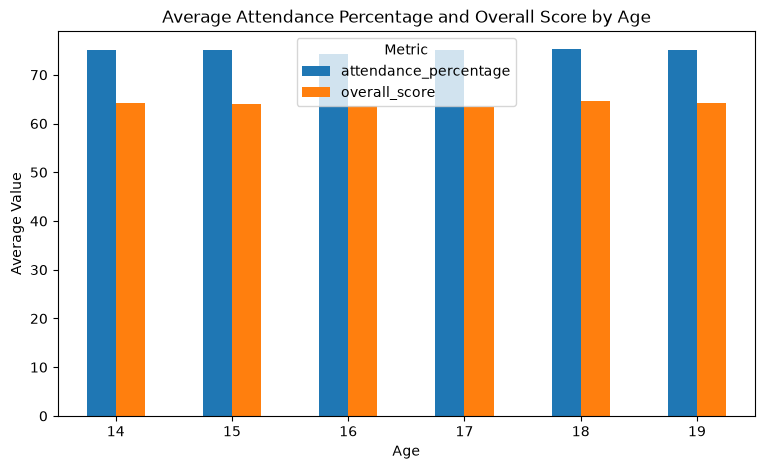

In [39]:
grouped_df.plot(kind="bar",figsize=(9,5) , title="Average Attendance Percentage and Overall Score by Age")
plt.xlabel("Age")
plt.ylabel("Average Value")
plt.xticks(rotation=0)
plt.legend(title="Metric")
plt.show()

# Does gender and school type influence students’ academic performance?
Female students show slightly higher overall scores compared to male and other gender groups across both school types. However, performance differences between school types remain relatively moderate, suggesting that gender-related performance gaps are present but not substantial.

In [40]:
grouped_gender=df.groupby(["gender","school_type"])["overall_score"].mean().sort_values(ascending=False)
grouped_gender

gender  school_type
female  public         64.599261
        private        64.107193
other   private        64.028374
male    private        63.972619
        public         63.928016
other   public         63.471770
Name: overall_score, dtype: float64

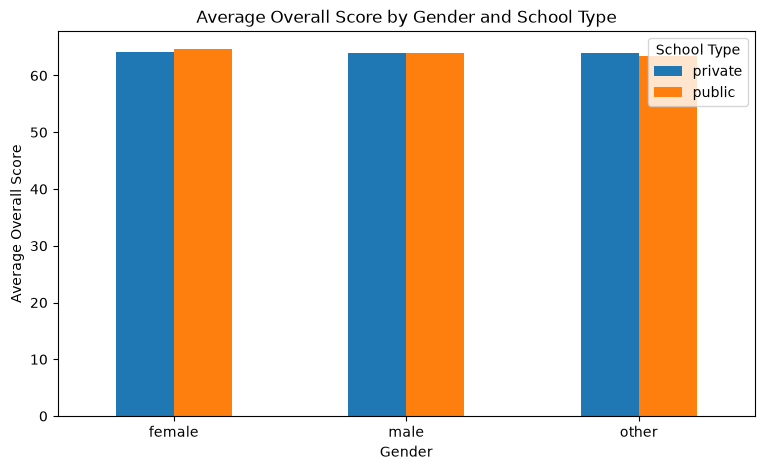

In [41]:
pivot_df = df.pivot_table(
    values="overall_score",
    index="gender",
    columns="school_type",
    aggfunc="mean"
)

pivot_df.plot(
    kind="bar",
    figsize=(9,5),
    title="Average Overall Score by Gender and School Type"
)

plt.xlabel("Gender")
plt.ylabel("Average Overall Score")
plt.xticks(rotation=0)
plt.legend(title="School Type")
plt.show()


# Does parents' education level influence student performance?
Students whose parents have higher education levels, such as diploma or postgraduate degrees, tend to achieve slightly higher overall scores. This suggests that parental education can have a modest positive impact on academic performance.

In [42]:
parent_education=df.groupby("parent_education")["overall_score"].mean().sort_values(ascending=False)
parent_education

parent_education
diploma          64.773382
post graduate    64.303748
graduate         63.946393
phd              63.938417
no formal        63.653006
high school      63.445972
Name: overall_score, dtype: float64

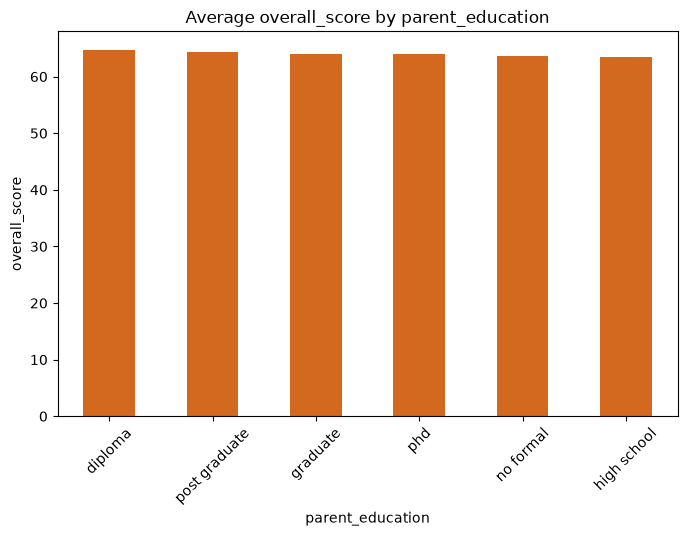

In [43]:
parent_education.plot(kind="bar" , figsize=(8,5) , title="Average overall_score by parent_education" , color="#D2691E")
plt.xlabel("parent_education")
plt.ylabel("overall_score")
plt.xticks(rotation=45)
plt.show()

# Does internet access and participation in extra activities affect student performance?
Students without internet access but participating in extra activities achieve the highest overall scores, while students with internet access but no extra activities follow closely. This suggests that engagement in extra-curricular activities may have a positive impact on performance, sometimes even outweighing internet availability.

In [44]:
df.groupby(["internet_access","extra_activities"])["overall_score"].mean().sort_values(ascending=False)

internet_access  extra_activities
0                1                   64.436627
1                0                   64.090005
                 1                   63.997340
0                0                   63.295888
Name: overall_score, dtype: float64

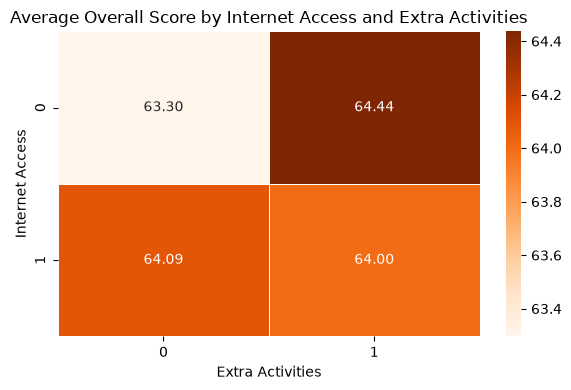

In [45]:
import seaborn as sns
import matplotlib.pyplot as plt

pivot_df = df.pivot_table(
    values="overall_score",
    index="internet_access",
    columns="extra_activities",
    aggfunc="mean"
)

plt.figure(figsize=(6,4))

sns.heatmap(
    pivot_df,
    annot=True,
    fmt=".2f",
    cmap="Oranges",   
    linewidths=0.5
)

plt.title("Average Overall Score by Internet Access and Extra Activities")
plt.xlabel("Extra Activities")
plt.ylabel("Internet Access")
plt.tight_layout()
plt.show()


# Which study method leads to the best academic performance?
Students using online videos and coaching methods achieve the highest overall scores, suggesting that digital learning resources and guided coaching are more effective than traditional methods like notes, textbooks, or group study.

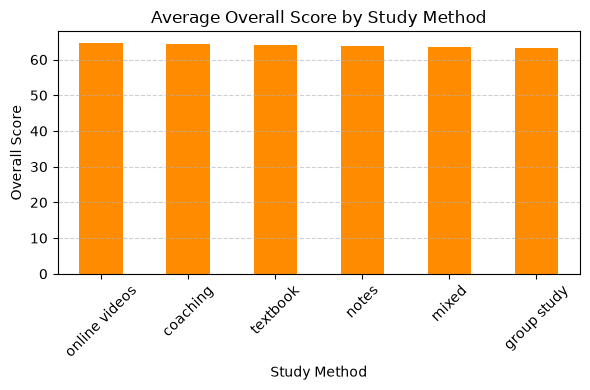

In [46]:
import matplotlib.pyplot as plt

study_method = df.groupby("study_method")["overall_score"].mean().sort_values(ascending=False)

plt.figure(figsize=(6,4))

study_method.plot(
    kind="bar",
    title="Average Overall Score by Study Method",
    color="darkorange"   
)

plt.xlabel("Study Method")
plt.ylabel("Overall Score")
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


#  Study Hours and Academic Performance
This analysis examines how students' overall scores vary according to the number of hours they dedicate to studying.

Results show a strong positive correlation: students who study more hours tend to achieve higher scores, with the highest averages observed around 8 study hours per day.

In [47]:
df.groupby("study_hours")["overall_score"].mean().sort_values(ascending=False).head(20)

study_hours
8.0    93.503093
7.9    92.286000
7.8    91.808808
7.6    90.883645
7.7    90.837264
7.4    89.444550
7.5    89.066832
7.3    87.623671
7.2    86.753535
7.1    85.791500
7.0    85.611168
6.9    84.655959
6.7    83.474611
6.8    83.076733
6.5    82.645000
6.6    82.413953
6.4    81.628241
6.3    80.809045
6.1    79.750725
6.2    78.882383
Name: overall_score, dtype: float64

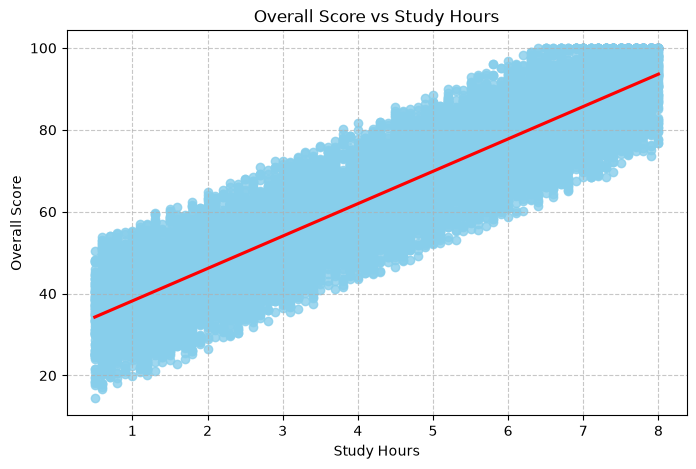

In [48]:
plt.figure(figsize=(8,5))
sns.regplot(x="study_hours", y="overall_score", data=df, scatter_kws={"color":"skyblue"}, line_kws={"color":"red"})
plt.title("Overall Score vs Study Hours")
plt.xlabel("Study Hours")
plt.ylabel("Overall Score")
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()


# Does higher attendance guarantee better academic performance?
Higher attendance does not always translate into higher overall scores. While attendance is important, other factors such as study hours, study methods, and engagement in extra activities appear to have a stronger impact on students' academic performance.

In [49]:
df.groupby("attendance_percentage")["overall_score"].mean().sort_values(ascending=False).head(20)

attendance_percentage
90.9    80.660870
97.7    77.925926
98.6    77.725000
98.0    77.409677
97.5    76.960870
93.4    76.617241
88.0    76.552000
96.3    76.427778
99.4    76.412121
94.2    76.334783
99.6    76.286667
90.0    76.260870
94.6    76.176316
98.8    75.933333
93.5    75.846154
96.9    75.738095
90.3    75.384848
86.9    75.285714
97.6    75.096296
99.3    74.900000
Name: overall_score, dtype: float64

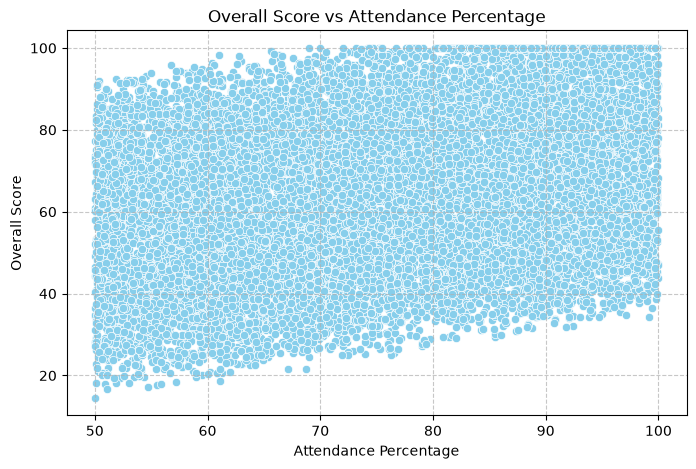

In [50]:
plt.figure(figsize=(8,5))
sns.scatterplot(x="attendance_percentage", y="overall_score", data=df, color="skyblue")
plt.title("Overall Score vs Attendance Percentage")
plt.xlabel("Attendance Percentage")
plt.ylabel("Overall Score")
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()


# Do students perform better in one subject over others?
Students perform almost equally across Math, Science, and English, indicating a balanced performance without any single subject showing a significant advantage or weakness.

math_score       63.774553
science_score    63.751227
english_score    63.709227
dtype: float64


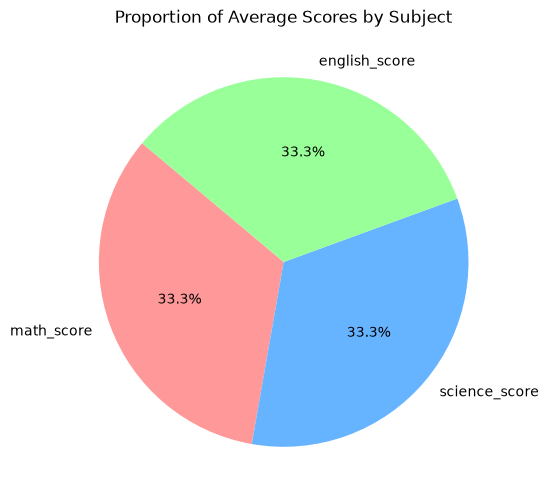

In [51]:
subject_avg = df[["math_score", "science_score", "english_score"]].mean().sort_values(ascending=False)
print(subject_avg)
plt.figure(figsize=(6,6))
plt.pie(subject_avg, labels=subject_avg.index, autopct='%1.1f%%', colors=["#FF9999","#66B3FF","#99FF99"], startangle=140)
plt.title("Proportion of Average Scores by Subject")
plt.show()


# How are students distributed across final grades?
The majority of students fall into the [most common grade] category, while fewer students achieve the highest or lowest grades. This distribution helps identify overall performance trends and areas where academic support might be needed.

final_grade
a     721
b    1638
c    3697
d    3770
e    3378
f    1796
Name: count, dtype: int64


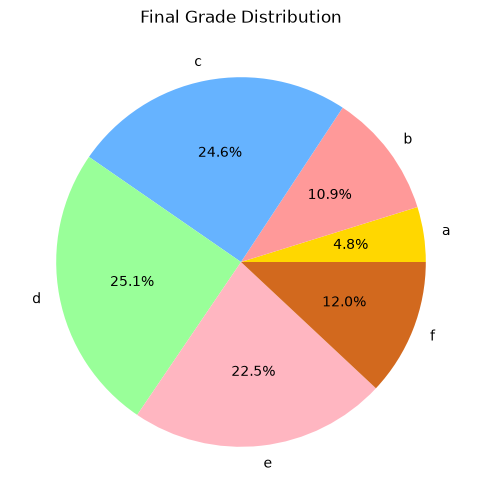

In [ ]:
grade_counts = df["final_grade"].value_counts().sort_index()
print(grade_counts)
plt.figure(figsize=(6,6)) 
plt.pie(grade_counts, labels=grade_counts.index, autopct='%1.1f%%', colors=["#FFD700","#FF9999","#66B3FF","#99FF99","#FFB6C1","#D2691E"]) 
plt.title("Final Grade Distribution") 
plt.show()